In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Project paths
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "output" / "cleaned_student_habits.csv"

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

# Chart styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (35, 23)


,timestamp,age,gender,level_of_study,program_stream,current_cgpa_or_percentage,average_attendance_percentage,how_many_hours_do_you_study_outside_class_daily,how_many_days_per_week_do_you_study_consistently,when_do_you_usually_start_preparing_for_exams,...,do_you_exercise_regularly,average_physical_activity_per_week,how_would_you_rate_your_time_management_skills,how_often_do_you_procrastinate,how_stressed_do_you_feel_during_a_typical_semester,do_you_think_your_study_habits_affect_your_academic_performance,what_do_you_think_is_the_biggest_challenge_affecting_your_studies,time_management_category,study_category,attendance_category
0,2026-06-09 15:13:34+00:00,21.0,M,UG,BE-CSE,9.89,85.0,Less than 1 hour,6-7,One week before,...,No,NaN,Average,Sometimes,Moderate,Yes,Stressed about the question paper and the type...,Average,Low,High
1,2026-06-09 15:15:38+00:00,20.0,M,UG,B.E I.T,8.18,60.0,1-2 hours,0-1,One week before,...,No,NaN,Poor,Often,Very Low,Yes,Laziness,Poor,Moderate,Low
2,2026-06-09 15:18:28+00:00,20.0,M,UG,Information Technology,6.70,75.0,2-4 hours,2-3,One week before,...,No,3-4 days,Good,Sometimes,Moderate,No,It is hard to clear topic in a specific period...,Good,High,Moderate
3,2026-06-09 15:19:40+00:00,19.0,M,UG,Science,9.20,81.0,More than 6 hours,6-7,Throughout the semester,...,No,NaN,Excllent,Often,Low,Yes,Time management,Excellent,Very High,High
4,2026-06-09 15:22:26+00:00,20.0,M,UG,It,8.00,84.0,Less than 1 hour,2-3,One day before,...,No,3-4 days,Average,Often,Low,No,Her,Average,Low,High


## 1. Dataset Overview

This section examines the dimensions, structure, and data types of the cleaned student study habits dataset.

In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
display(pd.DataFrame({"Column": df.columns}))

print("\nData types and non-null counts:")
df.info()

Number of rows: 35
Number of columns: 23

Column names:


,Column
0,timestamp
1,age
2,gender
3,level_of_study
4,program_stream
5,current_cgpa_or_percentage
6,average_attendance_percentage
7,how_many_hours_do_you_study_outside_class_daily
8,how_many_days_per_week_do_you_study_consistently
9,when_do_you_usually_start_preparing_for_exams



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 23 columns):
 #   Column                                                             Non-Null Count  Dtype  
---  ------                                                             --------------  -----  
 0   timestamp                                                          35 non-null     str    
 1   age                                                                35 non-null     float64
 2   gender                                                             35 non-null     str    
 3   level_of_study                                                     35 non-null     str    
 4   program_stream                                                     35 non-null     str    
 5   current_cgpa_or_percentage                                         35 non-null     float64
 6   average_attendance_percentage                                      35 non-null     float64
 7   how_ma

## 2. Summary Statistics

This section summarizes the numerical variables in the dataset.

In [3]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,35,35,2026-06-09 15:13:34+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,35.0,NaN,NaN,NaN,20.285714,1.296407,16.0,20.0,20.0,21.0,24.0
gender,35,2,M,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
level_of_study,35,2,UG,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
program_stream,35,31,Science,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
current_cgpa_or_percentage,35.0,NaN,NaN,NaN,8.068286,0.907007,5.75,7.565,8.1,8.6,9.89
average_attendance_percentage,35.0,NaN,NaN,NaN,72.914286,14.709684,40.0,68.0,75.0,82.5,97.0
how_many_hours_do_you_study_outside_class_daily,35,5,1-2 hours,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
how_many_days_per_week_do_you_study_consistently,35,4,4-5,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
when_do_you_usually_start_preparing_for_exams,35,4,One week before,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data Quality and Missing Values

This section identifies columns with missing values to understand the completeness of the survey responses.

,Missing Values,Missing Percentage
average_physical_activity_per_week,10,28.57
what_do_you_think_is_the_biggest_challenge_affecting_your_studies,7,20.00
how_often_do_you_procrastinate,2,5.71


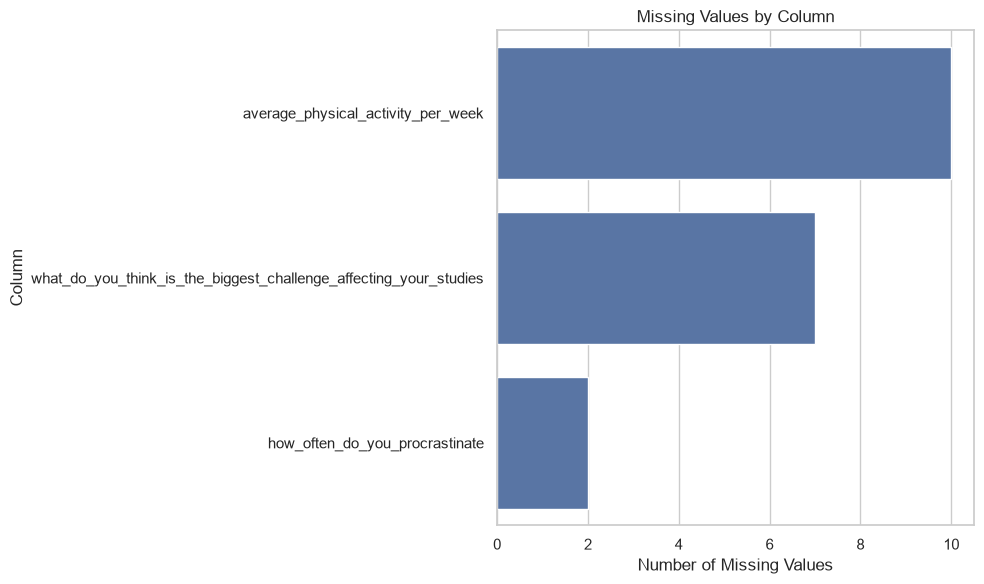

In [4]:
missing_count = df.isnull().sum()
missing_count = missing_count[missing_count > 0].sort_values(
    ascending=False
)

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": (
        missing_count / len(df) * 100
    ).round(2)
})

display(missing_summary)

if not missing_count.empty:
    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=missing_count.values,
        y=missing_count.index
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

## 4. Daily Study Hours Distribution

This section examines the daily study-hour categories reported by students.

,Student Count
how_many_hours_do_you_study_outside_class_daily,
1-2 hours,12
Less than 1 hour,10
2-4 hours,7
4-6 hours,4
More than 6 hours,2


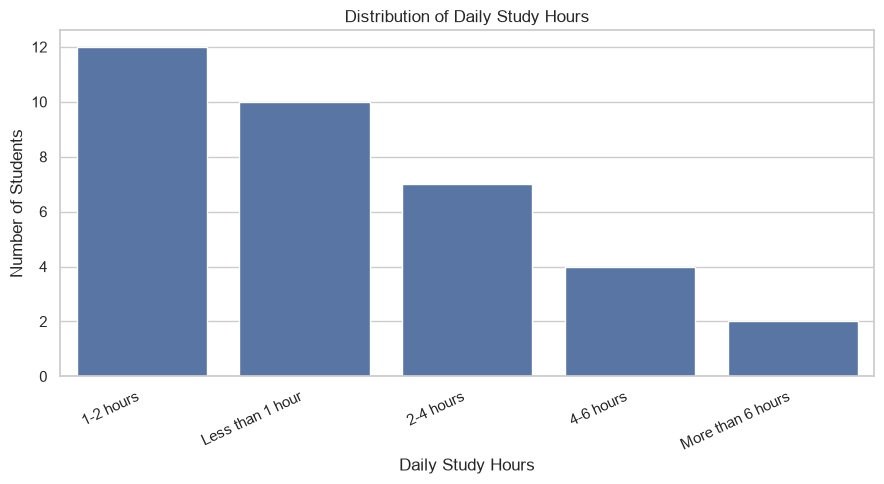

In [5]:
study_col = "how_many_hours_do_you_study_outside_class_daily"

study_counts = (
    df[study_col]
    .fillna("Not reported")
    .value_counts()
)

display(study_counts.rename("Student Count").to_frame())

plt.figure(figsize=(9, 5))
sns.barplot(
    x=study_counts.index,
    y=study_counts.values
)

plt.title("Distribution of Daily Study Hours")
plt.xlabel("Daily Study Hours")
plt.ylabel("Number of Students")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 5. Attendance Analysis

This section explores student attendance percentages and the derived attendance categories.

Attendance summary:


count    35.000000
mean     72.914286
std      14.709684
min      40.000000
25%      68.000000
50%      75.000000
75%      82.500000
max      97.000000
Name: average_attendance_percentage, dtype: float64

,Student Count
attendance_category,
Low,8
Moderate,10
High,17
Not reported,0


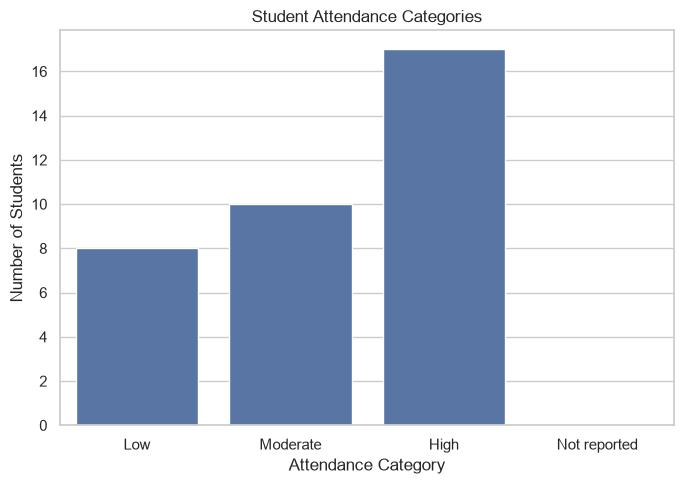

In [6]:
attendance_col = "average_attendance_percentage"

print("Attendance summary:")
display(df[attendance_col].describe())

attendance_counts = (
    df["attendance_category"]
    .fillna("Not reported")
    .value_counts()
    .reindex(
        ["Low", "Moderate", "High", "Not reported"],
        fill_value=0
    )
)

display(attendance_counts.rename("Student Count").to_frame())

plt.figure(figsize=(7, 5))
sns.barplot(
    x=attendance_counts.index,
    y=attendance_counts.values
)

plt.title("Student Attendance Categories")
plt.xlabel("Attendance Category")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

## 6. Procrastination Analysis

This section examines how frequently students report procrastinating.

,Student Count
how_often_do_you_procrastinate,
Sometimes,9
Often,9
Very Often,8
Rarely,5
Not reported,2
Never,2


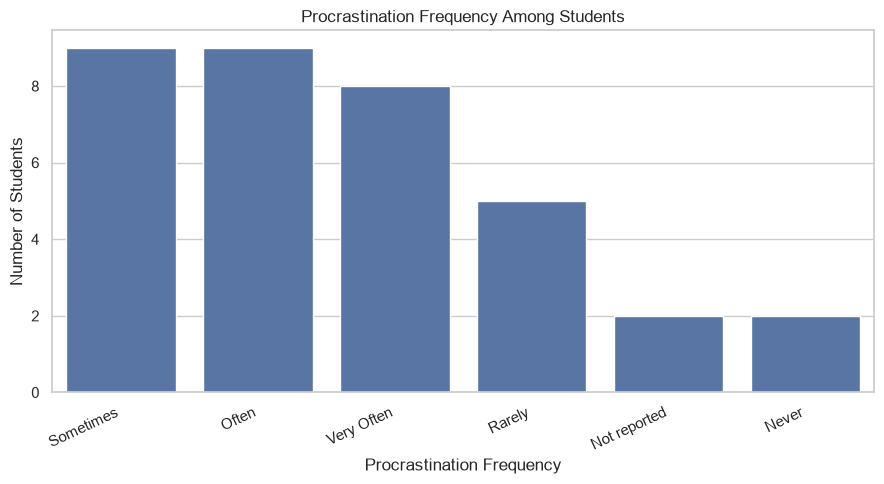

In [7]:
procrastination_col = "how_often_do_you_procrastinate"

procrastination_counts = (
    df[procrastination_col]
    .fillna("Not reported")
    .value_counts()
)

display(
    procrastination_counts.rename("Student Count").to_frame()
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=procrastination_counts.index,
    y=procrastination_counts.values
)

plt.title("Procrastination Frequency Among Students")
plt.xlabel("Procrastination Frequency")
plt.ylabel("Number of Students")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. Time Management Analysis

This section examines students' self-reported time-management skills.

,Student Count
time_management_category,
Average,17
Poor,8
Good,6
Excellent,4


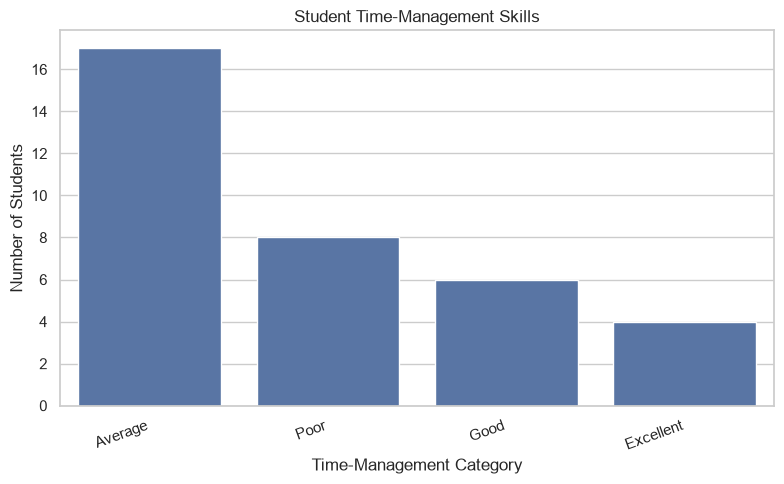

In [9]:
time_management_counts = (
    df["time_management_category"]
    .fillna("Not reported")
    .value_counts()
)

display(
    time_management_counts.rename("Student Count").to_frame()
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=time_management_counts.index,
    y=time_management_counts.values
)

plt.title("Student Time-Management Skills")
plt.xlabel("Time-Management Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Preferred Study Methods

This section identifies the study methods most frequently reported by students.

,Student Count
preferred_study_method,
Reading notes,15
Watching videos,10
Solving problems,4
Group study,3
Others,3


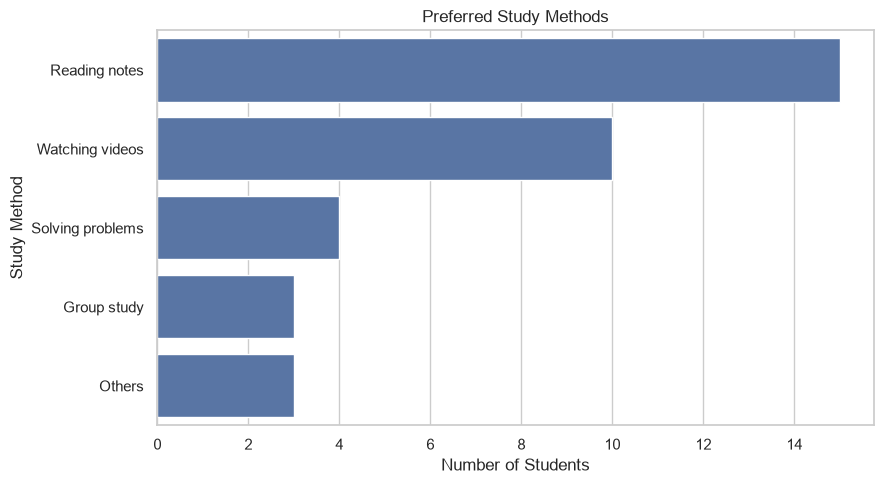

In [10]:
method_col = "preferred_study_method"

method_counts = (
    df[method_col]
    .fillna("Not reported")
    .value_counts()
)

display(method_counts.rename("Student Count").to_frame())

plt.figure(figsize=(9, 5))
sns.barplot(
    x=method_counts.values,
    y=method_counts.index
)

plt.title("Preferred Study Methods")
plt.xlabel("Number of Students")
plt.ylabel("Study Method")
plt.tight_layout()
plt.show()

## 9. Academic Score Data Check

The survey records academic performance as CGPA or percentage. These values must be checked for consistency before comparing averages.

In [11]:
score_col = "current_cgpa_or_percentage"

print("Recorded academic score summary:")
display(df[score_col].describe())

print("\nDistinct recorded values:")
display(
    df[score_col]
    .dropna()
    .sort_values()
    .to_frame()
    .reset_index(drop=True)
)

Recorded academic score summary:


count    35.000000
mean      8.068286
std       0.907007
min       5.750000
25%       7.565000
50%       8.100000
75%       8.600000
max       9.890000
Name: current_cgpa_or_percentage, dtype: float64


Distinct recorded values:


,current_cgpa_or_percentage
0,5.75
1,6.32
2,6.60
3,6.70
4,7.00
5,7.00
6,7.38
7,7.50
8,7.50
9,7.63


## 10. Conclusion

This exploratory analysis examines student study-hour categories, attendance, procrastination, time-management skills, preferred study methods, and missing data.

The charts summarize patterns in the available survey responses. The dataset contains only 35 student records, so the findings should be treated as exploratory rather than representative of all students.

Further analysis of academic performance requires verifying that CGPA and percentage values use a consistent scale.